# Nondeterministic Actions: Solving Tic-Tac-Toe with AND-OR-Tree Search

## Introduction 
 
Multiplayer games can be implemented as:
1. __Nondeterministic actions:__ The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)).

We will implement
* __AND-OR-Tree search.__

Each action consists of the move by the player (OR levels in the tree) and all possible (i.e., nondeterministic) responses by the opponents (AND levels). The action therefore results in a set of possible states.

We will search for a __conditional plan__ using AND-OR-Tree search. 

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Solving Tic-Tac-Toe using AND-OR-Tree Search

The opponent can be modeled as part of the environment. The opponent's action as a response to the agent's 
action makes the environment appear non-deterministic (see AIMA page 125 or the slides). The ADS-OR-Tree algorithm uses the following functions:

* `is_goal(state)`: determine if the current board/state has a winner.
* `is_cycle(path)`: determine if we are in a loop (the tic-tac-toe problem has no loops so I do not implement it).
* `results(state, action)`: returns all states following state + action.


### Cycles

The path is typically used for loop checking. We ignore it here since tic-tac-toe does not have cycles.

### Goals

Reaching the goal means that the agent has successfully finished the task. 

For games, `terminal(s)` checks if `s` is a terminal state, but a terminal state can also indicate that 
the player lost (which indicates a failure). This can determined by the 
`utility(s)` function. Tic-tac-toe also has draws and we need to decide if a draw is considered successfully reaching
the goal or a failure.

### Non-deterministic Results

Since the opponent and her moves are part of the environment, `results()` returns for a state $\times$ action combination a set of new states that reflects all possible responses by the opponent.

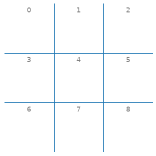


Set of possible state for placing an x at position 4 of an empty board and the opponent's move:


[['o', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', 'o', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', 'o', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', 'o', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', 'o', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', 'o', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', 'o']]

In [3]:
def results(state, action, player = 'x'):
    """produce the set of states after the provided action for player. 
       It is the set of boards with the action and all possible reactions by the opponent."""
    
    opponent = other(player)
    state = state.copy()
    
    # player's move
    state[action] = player
    
    # opponent reacts
    r = list()
    o_actions = actions(state)
    
    # board is full
    if len(o_actions) < 1 : return [state]
    
    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)    
    
    return r

show_board(empty_board())

print()
print("Set of possible state for placing an x at position 4 of an empty board and the opponent's move:")
results(empty_board(), 4)

### Recursive AND-OR Search (DFS)

In [4]:
# define global variables for debugging
DEBUG = 1
COUNT = 0 # used to report the number of searched nodes

def and_or_search(state, player = 'x', draw_is_win = True):
    """start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0
    
    plan = or_search(state, player, draw_is_win)
    
    if DEBUG >= 1: 
        print(f"Number of nodes searched: {COUNT}")  
    
    return plan
 

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move. 
    We try all possible action and return a conditional 
    plan for the first action that only has goal states as leaf nodes. 
    If none can be found, then failure (None) is returned.
    
    Note: path is not used in this implementation since tic-tac-toe does not 
    need cycle checking.
    """
    global DEBUG, COUNT
    COUNT += 1
    
    # goal check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None # failure
     
    # cycles check: tic-tac-toe has no cycles

    # check all possible actions
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: 
            return [action, plan]
    
    # failure
    return None


def and_search(states, player, draw_is_win):
    """And step of the search: Represents all opponent's possible moves. 
    Follow all possible states (call the or step). 
    Return a conditional plan only if all paths lead to a goal state."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return plans only if no state fails
    plans = []
    for s in states:
        # goal check
        u = utility(s, player)
        if u == 1: return "win"  # success
        if draw_is_win and u == 0: return "draw"

        plan = or_search(s, player, draw_is_win)
        
        if plan is None: 
            return None    # found a state that fails so we abandon this subtree!
        plans.append(['if', s, 'then', plan])
        
    return plans

And-or search looks for a subtree (i.e., an action) that guarantees a win and returns a conditional plan for this subtree. If no such subtree exists, no plan is returned. The algorithm only searches a fraction of the game tree since it abandons the current subtree when it finds the first leaf node that is not a win (see `and_search` function).

# Some Tests

## x is about to win

Board:


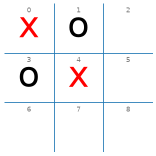


Win or draw:
Number of nodes searched: 22


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'],
   'then',
   [5,
    [['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]]]]

CPU times: total: 0 ns
Wall time: 3.01 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

Why does it play 2 and not 8!!!

In [6]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 30


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '], 'then', [8, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'], 'then', [6, 'win']]]]

CPU times: total: 0 ns
Wall time: 2.04 ms


**Nhận xét (X sắp thắng):** Với draw_is_win = True, AND-OR chọn nước 2, duyệt 22 nút trong 3,01 ms; với draw_is_win = False, vẫn chọn nước 2 nhưng duyệt 30 nút trong 2,04 ms. Kế hoạch có điều kiện: sau khi X đi 2 (đe dọa 2-4-6), mọi phản ứng của O đều được liệt kê thành nhánh 'if ... then ...'; nếu O không chặn ô 6 thì X đi 6 thắng, nếu O chặn thì X tiếp tục tạo thế thắng ở các nhánh sau. Lý do thuật toán chọn 2 mà không chọn 8 (thắng ngay trên đường chéo 0-4-8) là vì or_search duyệt các nước theo thứ tự tăng dần và trả về nước đầu tiên bảo đảm thắng; nó không tìm đường thắng ngắn nhất do bỏ qua chi phí đường đi.

## x can draw_is_win if it chooses 7

Board:


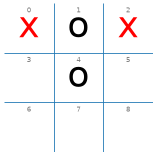


Win or draw:
Number of nodes searched: 64


[7,
 [['if',
   ['x', 'o', 'x', 'o', 'o', ' ', ' ', 'x', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'o', 'x', 'o', 'x', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'o', 'x', ' ', 'x', 'o'],
      'then',
      [6, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', 'o', ' ', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', 'o', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', ' ', 'o', 'x', 'o'],
      'then',
      [5, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', ' ', 'x', 'o'],
   'then',
   [3,
    [['if', ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'], 'then', [6, 'win']],
     ['if',
      ['x', '

CPU times: total: 15.6 ms
Wall time: 4.05 ms


In [7]:

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
#board[3] = 'o'
board[4] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [8]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 69


None

CPU times: total: 0 ns
Wall time: 2.01 ms


**Nhận xét (X có thể hòa nếu chọn 7):** Với draw_is_win = True, AND-OR chọn nước 7 (chặn O sắp thắng ở cột 1-4-7), duyệt 64 nút trong 4,05 ms; kế hoạch có các nhánh kết thúc bằng 'win' hoặc 'draw'. Với draw_is_win = False, AND-OR duyệt 69 nút trong 2,01 ms và trả về None vì không thể bảo đảm thắng. Như vậy việc coi hòa là thành công hay thất bại thay đổi hẳn kết quả (có kế hoạch hay None).

## a bad situation

Board:


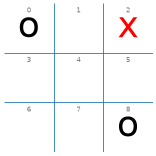


Win or draw:
Number of nodes searched: 155


None

CPU times: total: 0 ns
Wall time: 5.06 ms


In [9]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

**Nhận xét (tình huống bất lợi):** Với X ở ô 2 còn O ở ô 0 và 8, AND-OR duyệt 155 nút trong 5,06 ms và trả về None, nghĩa là không có kế hoạch bảo đảm thắng hoặc hòa. Khi đó and_or_player phải đi ngẫu nhiên, đây là hạn chế của AND-OR do không biết nước nào ít tệ nhất.

## Empty board: Only a draw_is_win can be guaranteed

Board:


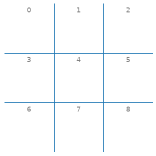


Win or draw:
Number of nodes searched: 966


[0,
 [['if',
   ['x', 'o', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
   'then',
   [2,
    [['if',
      ['x', 'o', 'x', 'o', ' ', ' ', ' ', ' ', ' '],
      'then',
      [4,
       [['if',
         ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '],
         'then',
         [6, 'win']],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
            'then',
            [7, 'draw']]]]],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
            'then',
            [6, 'win']]]]],
        ['if',
        

CPU times: total: 46.9 ms
Wall time: 46 ms


In [10]:
board = empty_board() 

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [11]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:


Number of nodes searched: 16213


None

CPU times: total: 422 ms
Wall time: 420 ms


**Nhận xét (bàn rỗng):** Với draw_is_win = True, AND-OR chọn nước 0 và tìm được kế hoạch sau khi duyệt 966 nút trong 46 ms, nghĩa là X luôn bảo đảm ít nhất hòa. Với draw_is_win = False (chỉ chấp nhận thắng), thuật toán duyệt 16213 nút trong 420 ms và trả về None, tức không có chiến lược bảo đảm thắng từ bàn rỗng nếu đối thủ đi đúng. Số nút và thời gian tăng mạnh vì khi không chấp nhận hòa, thuật toán không cắt nhánh sớm được.

## Experiments

### And-Or Tree Search vs. Random

Put AND-OR search into a wrapper agent function. Note that if AND-OR search cannot guarantee a win then
it does not return a plan, nut `None`. In this case, we do not know what the best (i.e., the least "bad") 
move is, so I make the agent play randomly. Other methods that we will learn about later can determine the utility of a move, even if it does not guarantee a win.

In [12]:
DEBUG = 0

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)

    # if there is no plan then we do a random action
    if plan is None: 
        return np.random.choice(actions(board))
    else:
        return plan[0]


print("and-or-search vs. random:")
%time display(play(and_or_player, random_player))

print()
print("random vs. and-or-search")
%time display(play(random_player, and_or_player))

and-or-search vs. random:


{'x': 93, 'o': 0, 'd': 7}

CPU times: total: 3.19 s
Wall time: 3.19 s

random vs. and-or-search


{'x': 0, 'o': 66, 'd': 34}

CPU times: total: 4.64 s
Wall time: 4.63 s


**Nhận xét:** and_or_player rất mạnh so với Random: khi đi trước thắng 93 ván, hòa 7 ván, thua 0 ván; khi đi sau thắng 66 ván, hòa 34 ván, thua 0 ván (mỗi chiều 100 ván). Tác tử không thua ván nào vì luôn tìm được kế hoạch bảo đảm thắng hoặc hòa; chỉ không thắng được khi Random vô tình chặn đúng. Nhược điểm là chậm: 100 ván mất 3,19 s (đi trước) và 4,63 s (đi sau) vì tác tử tìm kiếm lại từ đầu ở mỗi nước đi, trong khi Random gần như không tốn thời gian.

**Note how slow this is!**

My lazy implementation is a _simple reflex agent_ that recreates a conditional plan every time it is asked for an action. ut since And-Or search already produces a complete conditional plan for the empty board, a better implementation would use a _model-based reflex agent_ that store this precomputed plan and just follow it without more planing.

### And-Or Tree Search vs. And-Or Tree Search

In [13]:
# No randomness -> run only once

%time display(play(and_or_player, and_or_player, N = 1))

{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 78.1 ms
Wall time: 76.7 ms


**Nhận xét (AND-OR vs. AND-OR):** Hai tác tử AND-OR đấu với nhau cho kết quả hòa (1 ván hòa). Điều này khớp với lý thuyết: Tic-Tac-Toe là trò chơi hòa nếu cả hai đi tối ưu, và AND-OR (draw_is_win = True) luôn tìm được kế hoạch bảo đảm không thua. Ván đấu không có yếu tố ngẫu nhiên khi cả hai đều tìm được kế hoạch nên chỉ cần chạy một lần (Wall time khoảng 76,7 ms).

**Trả lời câu thảo luận 1 - Minimax khác AND-OR Search ở cách mô hình hóa đối thủ như thế nào?** Minimax mô hình hóa đối thủ là một tác tử đối kháng có chủ đích: đối thủ chọn nước đi làm tối thiểu hóa giá trị tiện ích của ta, và thuật toán trả về giá trị minimax cho từng nước đi (có thể so sánh được các nước đi với nhau, kể cả khi không thắng). AND-OR Search coi đối thủ là một phần của môi trường không xác định: nước đi của ta là nút OR (chỉ cần một lựa chọn tốt), còn mọi phản ứng có thể của đối thủ là nút AND (phải xử lý được tất cả). Kết quả là một kế hoạch có điều kiện (if-then) nếu bảo đảm được mục tiêu, hoặc None nếu không. AND-OR chỉ trả lời có/không về việc bảo đảm thắng (hoặc hòa); khi không có kế hoạch thì không biết nước nào ít tệ nhất, nên tác tử phải đi ngẫu nhiên. Ngược lại, Minimax cho giá trị cụ thể và phân biệt được nước đi tốt hơn trong tình huống bất lợi.